In [1]:
import sys, os
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

# Heavy Tails & Inference: Executive Analysis

Aryan Singh, Jaanvi, Nikhil — MDSE DS607 group coursework.

In [2]:
import pandas as pd
from pathlib import Path
from src.pipeline import run_all
run_all()

The master pipeline produces one reproducible local dataset, all final tables, and every required figure.

In [3]:
for name in sorted(Path("outputs/tables").glob("*.csv")):
    print("###", name.name)
    display(pd.read_csv(name))

### step10_chisq_extreme_days.csv


,Pair,00,01,10,11,Minimum expected count,All expected >= 5,Chi-square,p-value,Degrees of freedom
0,DBS-OCBC,2356,129,129,148,27.780232,True,642.703214,8.630423e-142,1
1,DBS-UOB,2363,122,122,155,27.780232,True,719.727172,1.534565e-158,1
2,OCBC-UOB,2373,112,112,165,27.780232,True,837.321151,4.149533e-184,1


### step10_permutation_tests.csv


,Bank,Comparison,Calm N,Stress N,Observed ratio,Two-sided empirical p,One-sided stress>calm p
0,DBS,Calm vs COVID,754,103,2.223054,0.000100,0.000100
1,DBS,Calm vs Rate Hike,754,499,0.943500,0.286871,0.856114
2,OCBC,Calm vs COVID,754,103,2.229882,0.000100,0.000100
3,OCBC,Calm vs Rate Hike,754,499,0.864694,0.014299,0.993401
4,UOB,Calm vs COVID,754,103,2.222365,0.000100,0.000100
5,UOB,Calm vs Rate Hike,754,499,0.994688,0.925807,0.528247


### step11_bayesian_vs_frequentist_cis.csv


,Pair A,Pair B,n_extreme_A,k_joint,Observed proportion,Wald low,Wald high,Bootstrap low,Bootstrap high,Beta flat low,Beta flat high,Skeptical low,Skeptical high,Jeffreys low,Jeffreys high
0,DBS,OCBC,277,148,0.534296,0.475553,0.593039,0.476534,0.592058,0.475435,0.592203,0.448293,0.561744,0.475452,0.592428
1,DBS,UOB,277,155,0.559567,0.501105,0.618029,0.501805,0.617329,0.500629,0.616847,0.471802,0.585072,0.500738,0.617158
2,OCBC,UOB,277,165,0.595668,0.537874,0.653461,0.537906,0.653430,0.536885,0.651789,0.505607,0.618178,0.537127,0.652221


... (12 outputs left out)

### step8_lrt_and_ks_tests.csv


,Bank,LRT_Lambda,LRT_parametric_bootstrap_p,Normal KS D,Normal KS bootstrap p,Student-t KS D,Student-t KS bootstrap p
0,DBS,381.055866,0.000999,0.061418,0.000999,0.014011,0.065934
1,OCBC,371.221985,0.000999,0.052021,0.000999,0.028998,0.000999
2,UOB,413.655124,0.000999,0.059720,0.000999,0.018984,0.000999


### step9_pearson_vs_kendall.csv


,Pair,Pearson rho,Pearson low,Pearson high,Pearson Fisher-z low,Pearson Fisher-z high,Pearson Fisher-z width,Kendall tau,Kendall low,Kendall high
0,DBS-OCBC,0.778430,0.752599,0.802542,0.763294,0.792712,0.029418,0.544910,0.525671,0.563658
1,DBS-UOB,0.758815,0.732311,0.783889,0.742533,0.774201,0.031668,0.530101,0.511212,0.548553
2,OCBC-UOB,0.776025,0.748233,0.801628,0.760747,0.790444,0.029697,0.542558,0.523491,0.561113


Each table is interpreted as follows: cleaning and EDA quantify heavy tails, CLT/bootstrap quantify uncertainty, distribution tests formalize Normal rejection, and dependence/regime tests quantify banking co-movement and tail clustering. Minimum values near -7σ to -9σ, excess kurtosis, Q-Q plots, and lower-tail log-CDF plots—not the 1% quantiles alone—support Normal rejection.

For Pearson correlation, Fisher-z CLT intervals are about 0.03 wide, e.g. DBS–OCBC [0.763, 0.793], while bootstrap intervals are about 0.05 wide, e.g. [0.753, 0.803]. Pearson and Kendall rank all pairs in the same order: DBS–OCBC highest, OCBC–UOB second, DBS–UOB third; Pearson and Kendall therefore operate on different scales and are not interchangeable.

step10_permutation_nulls.png


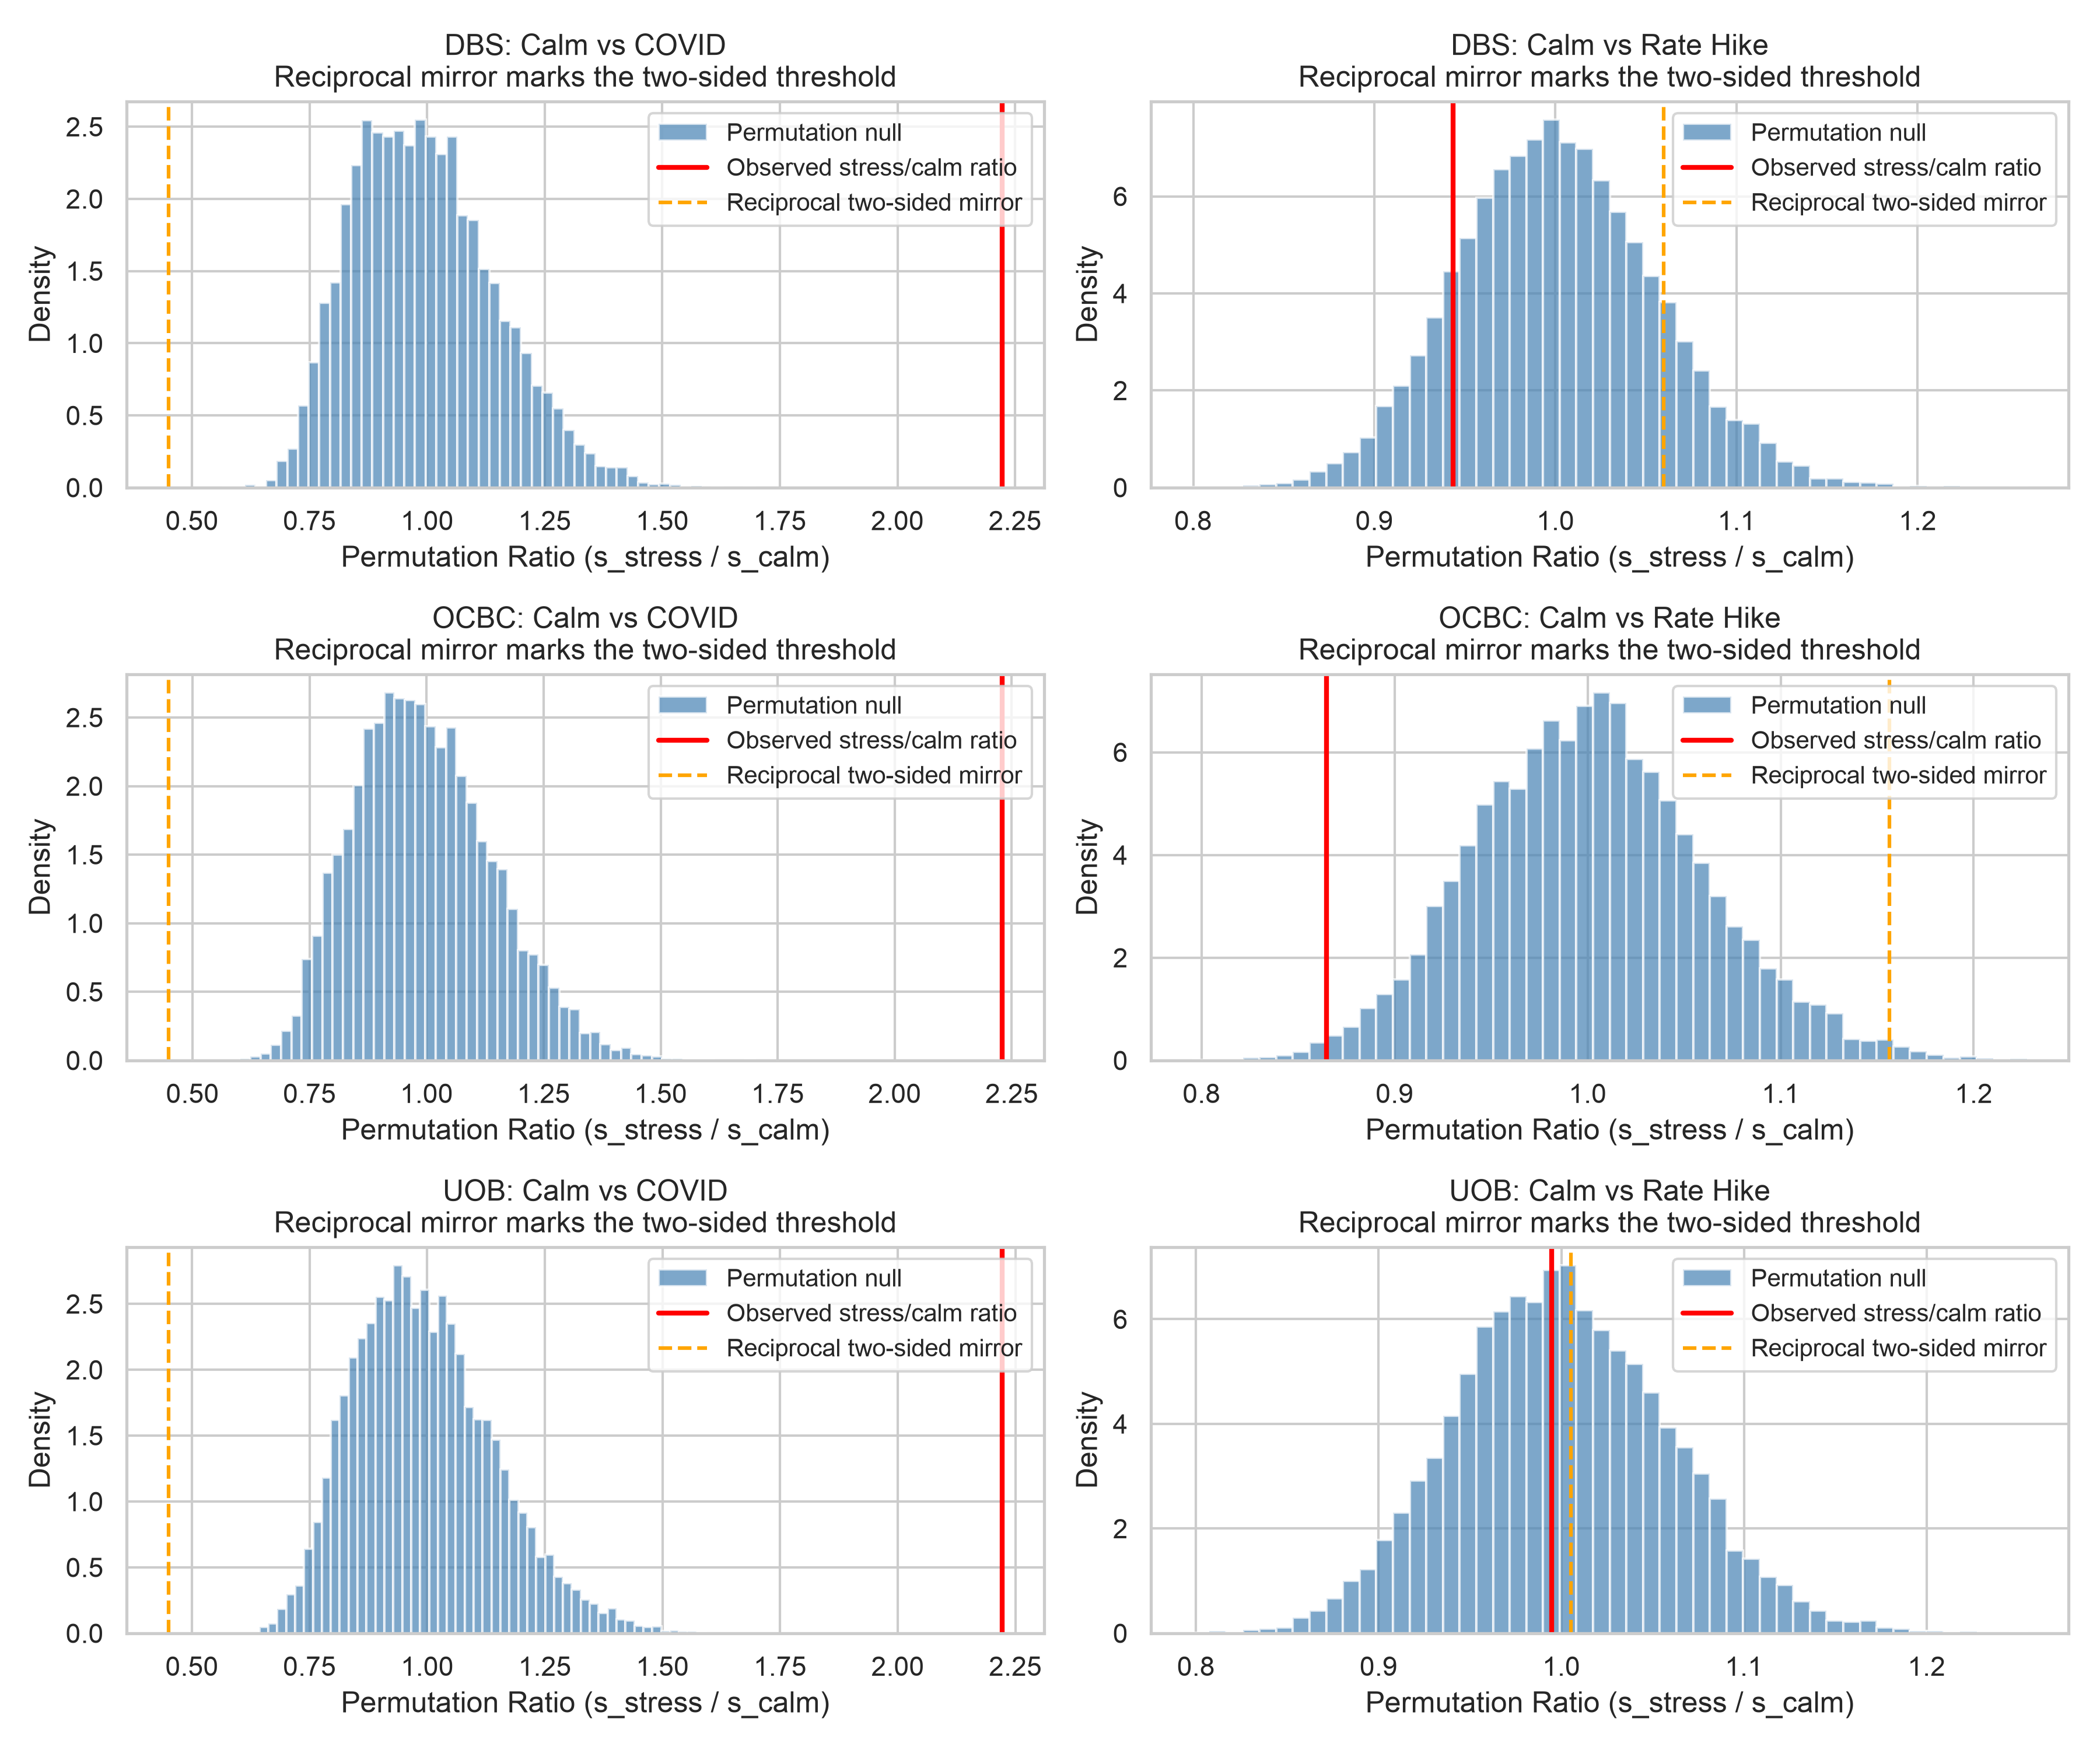

step11_bayesian_credible_intervals.png


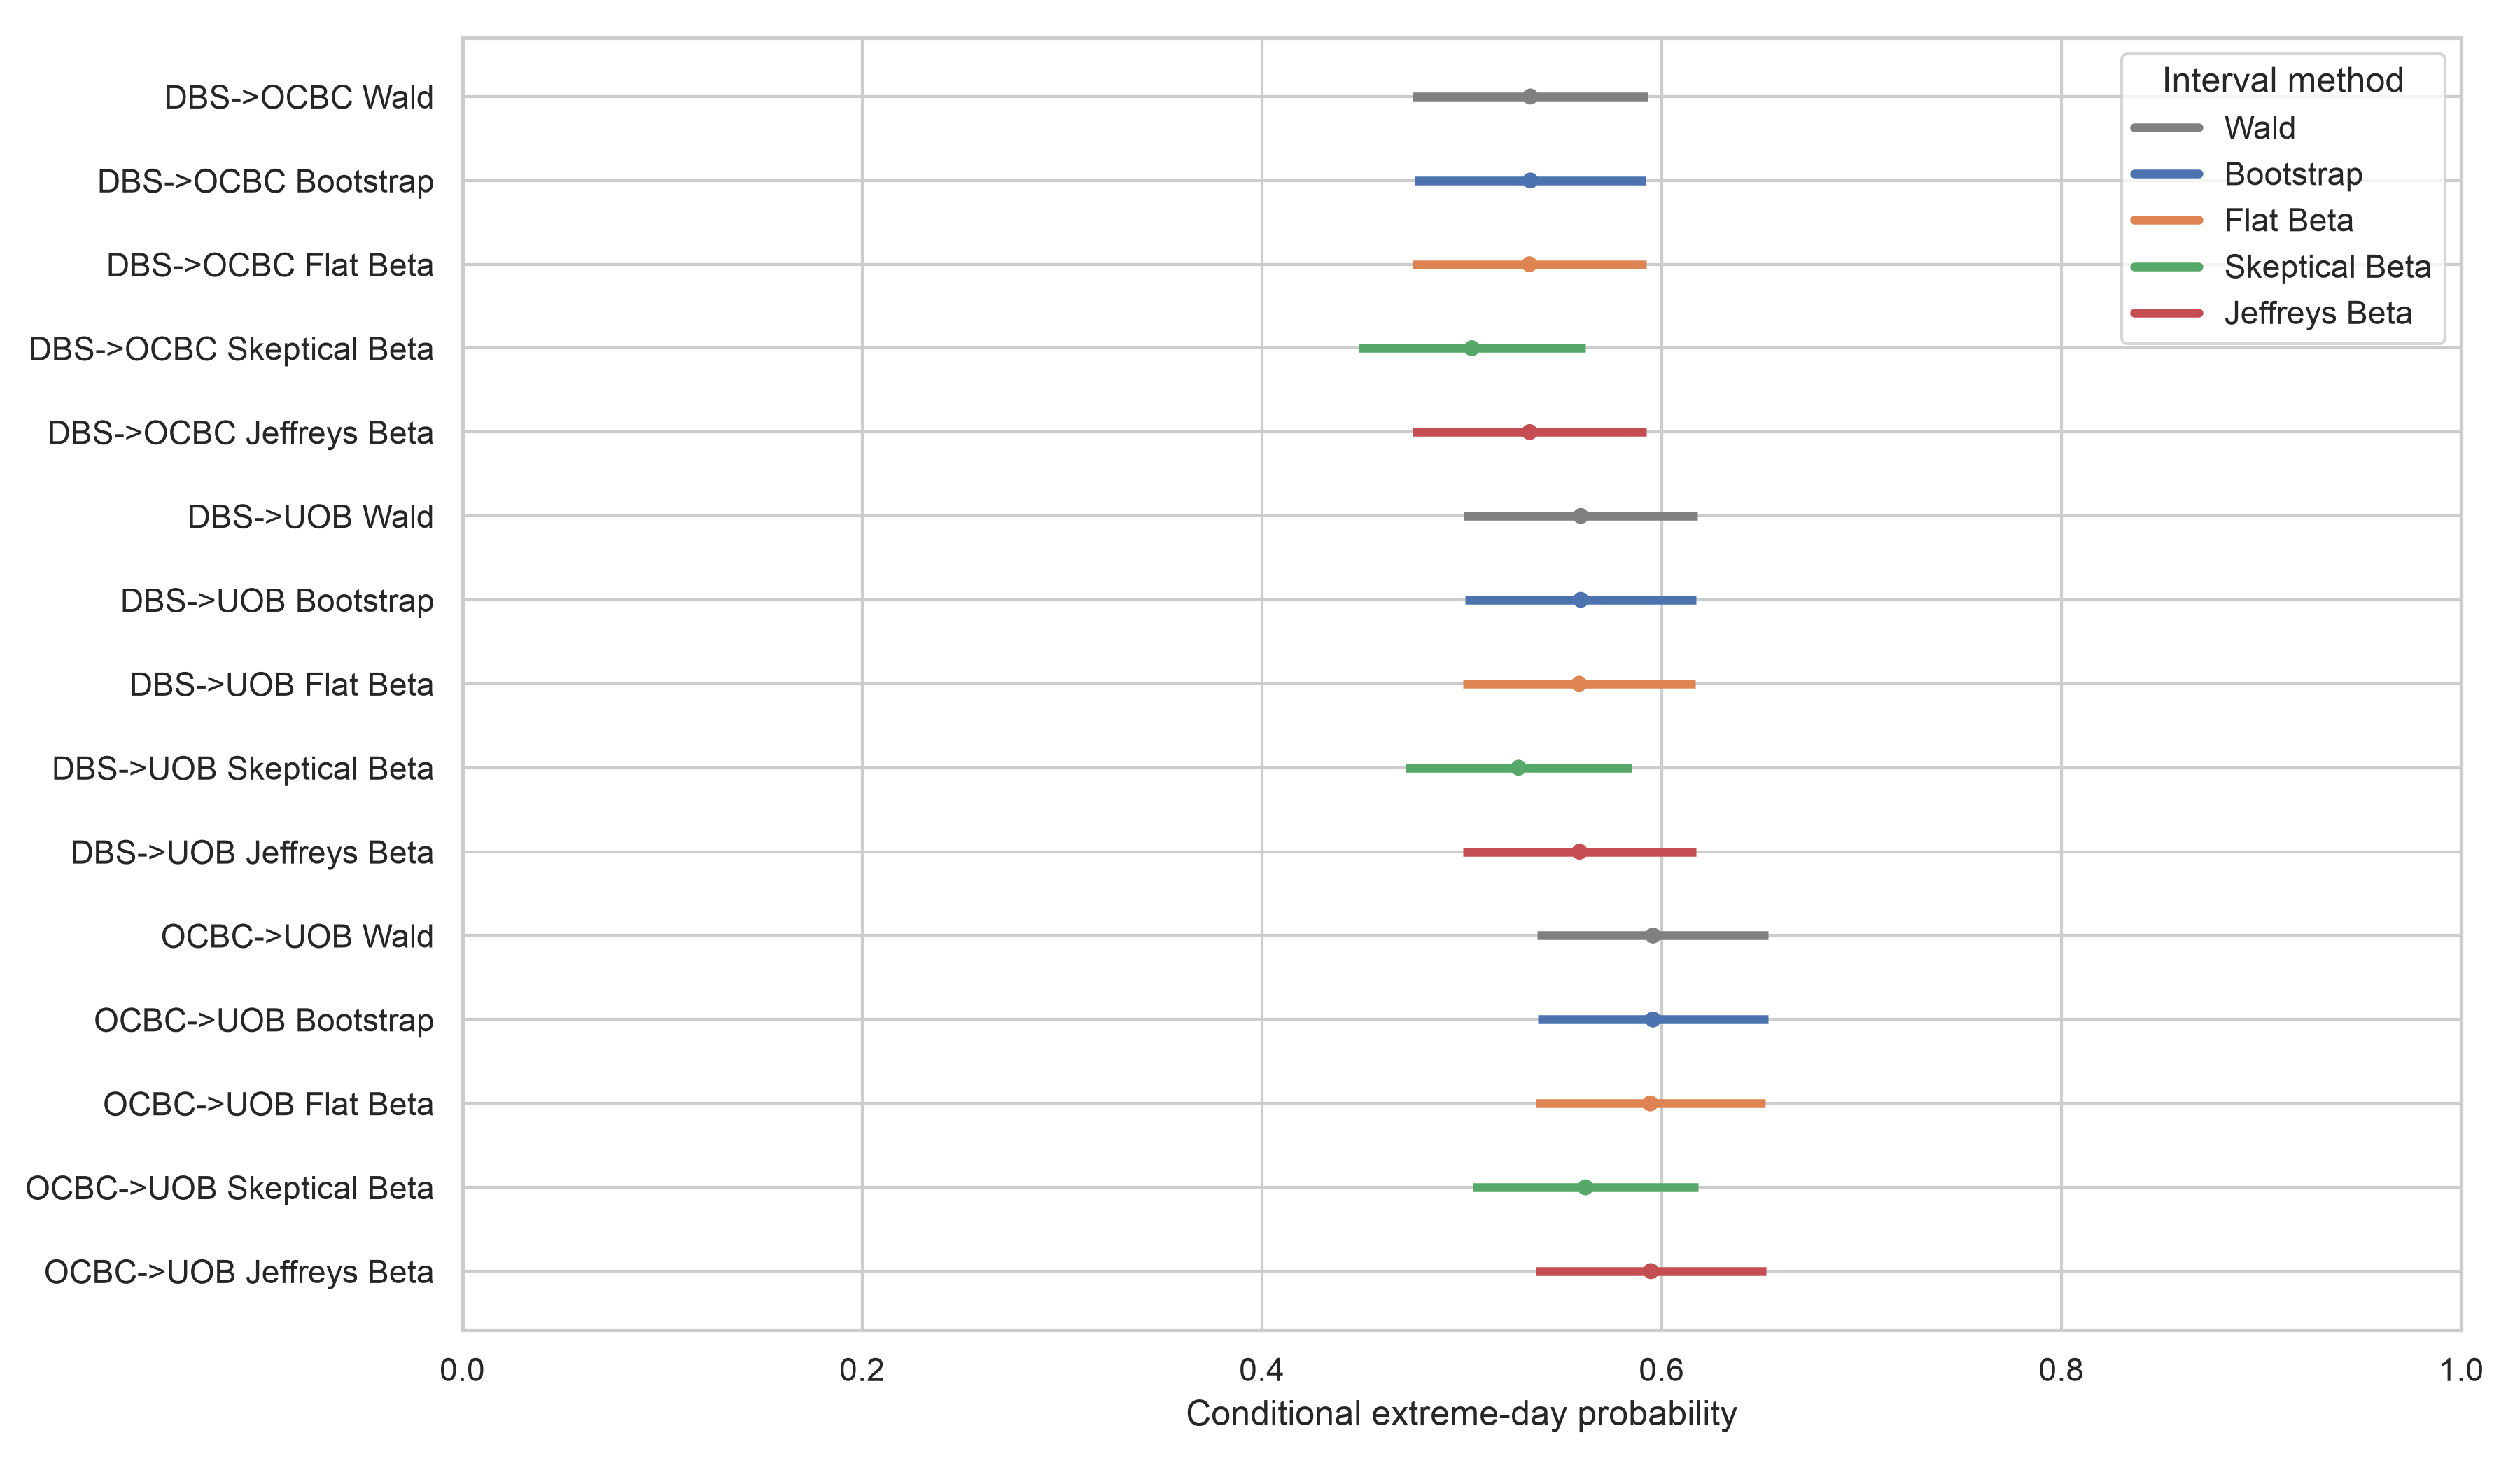

step4_ecdf_and_qq.png


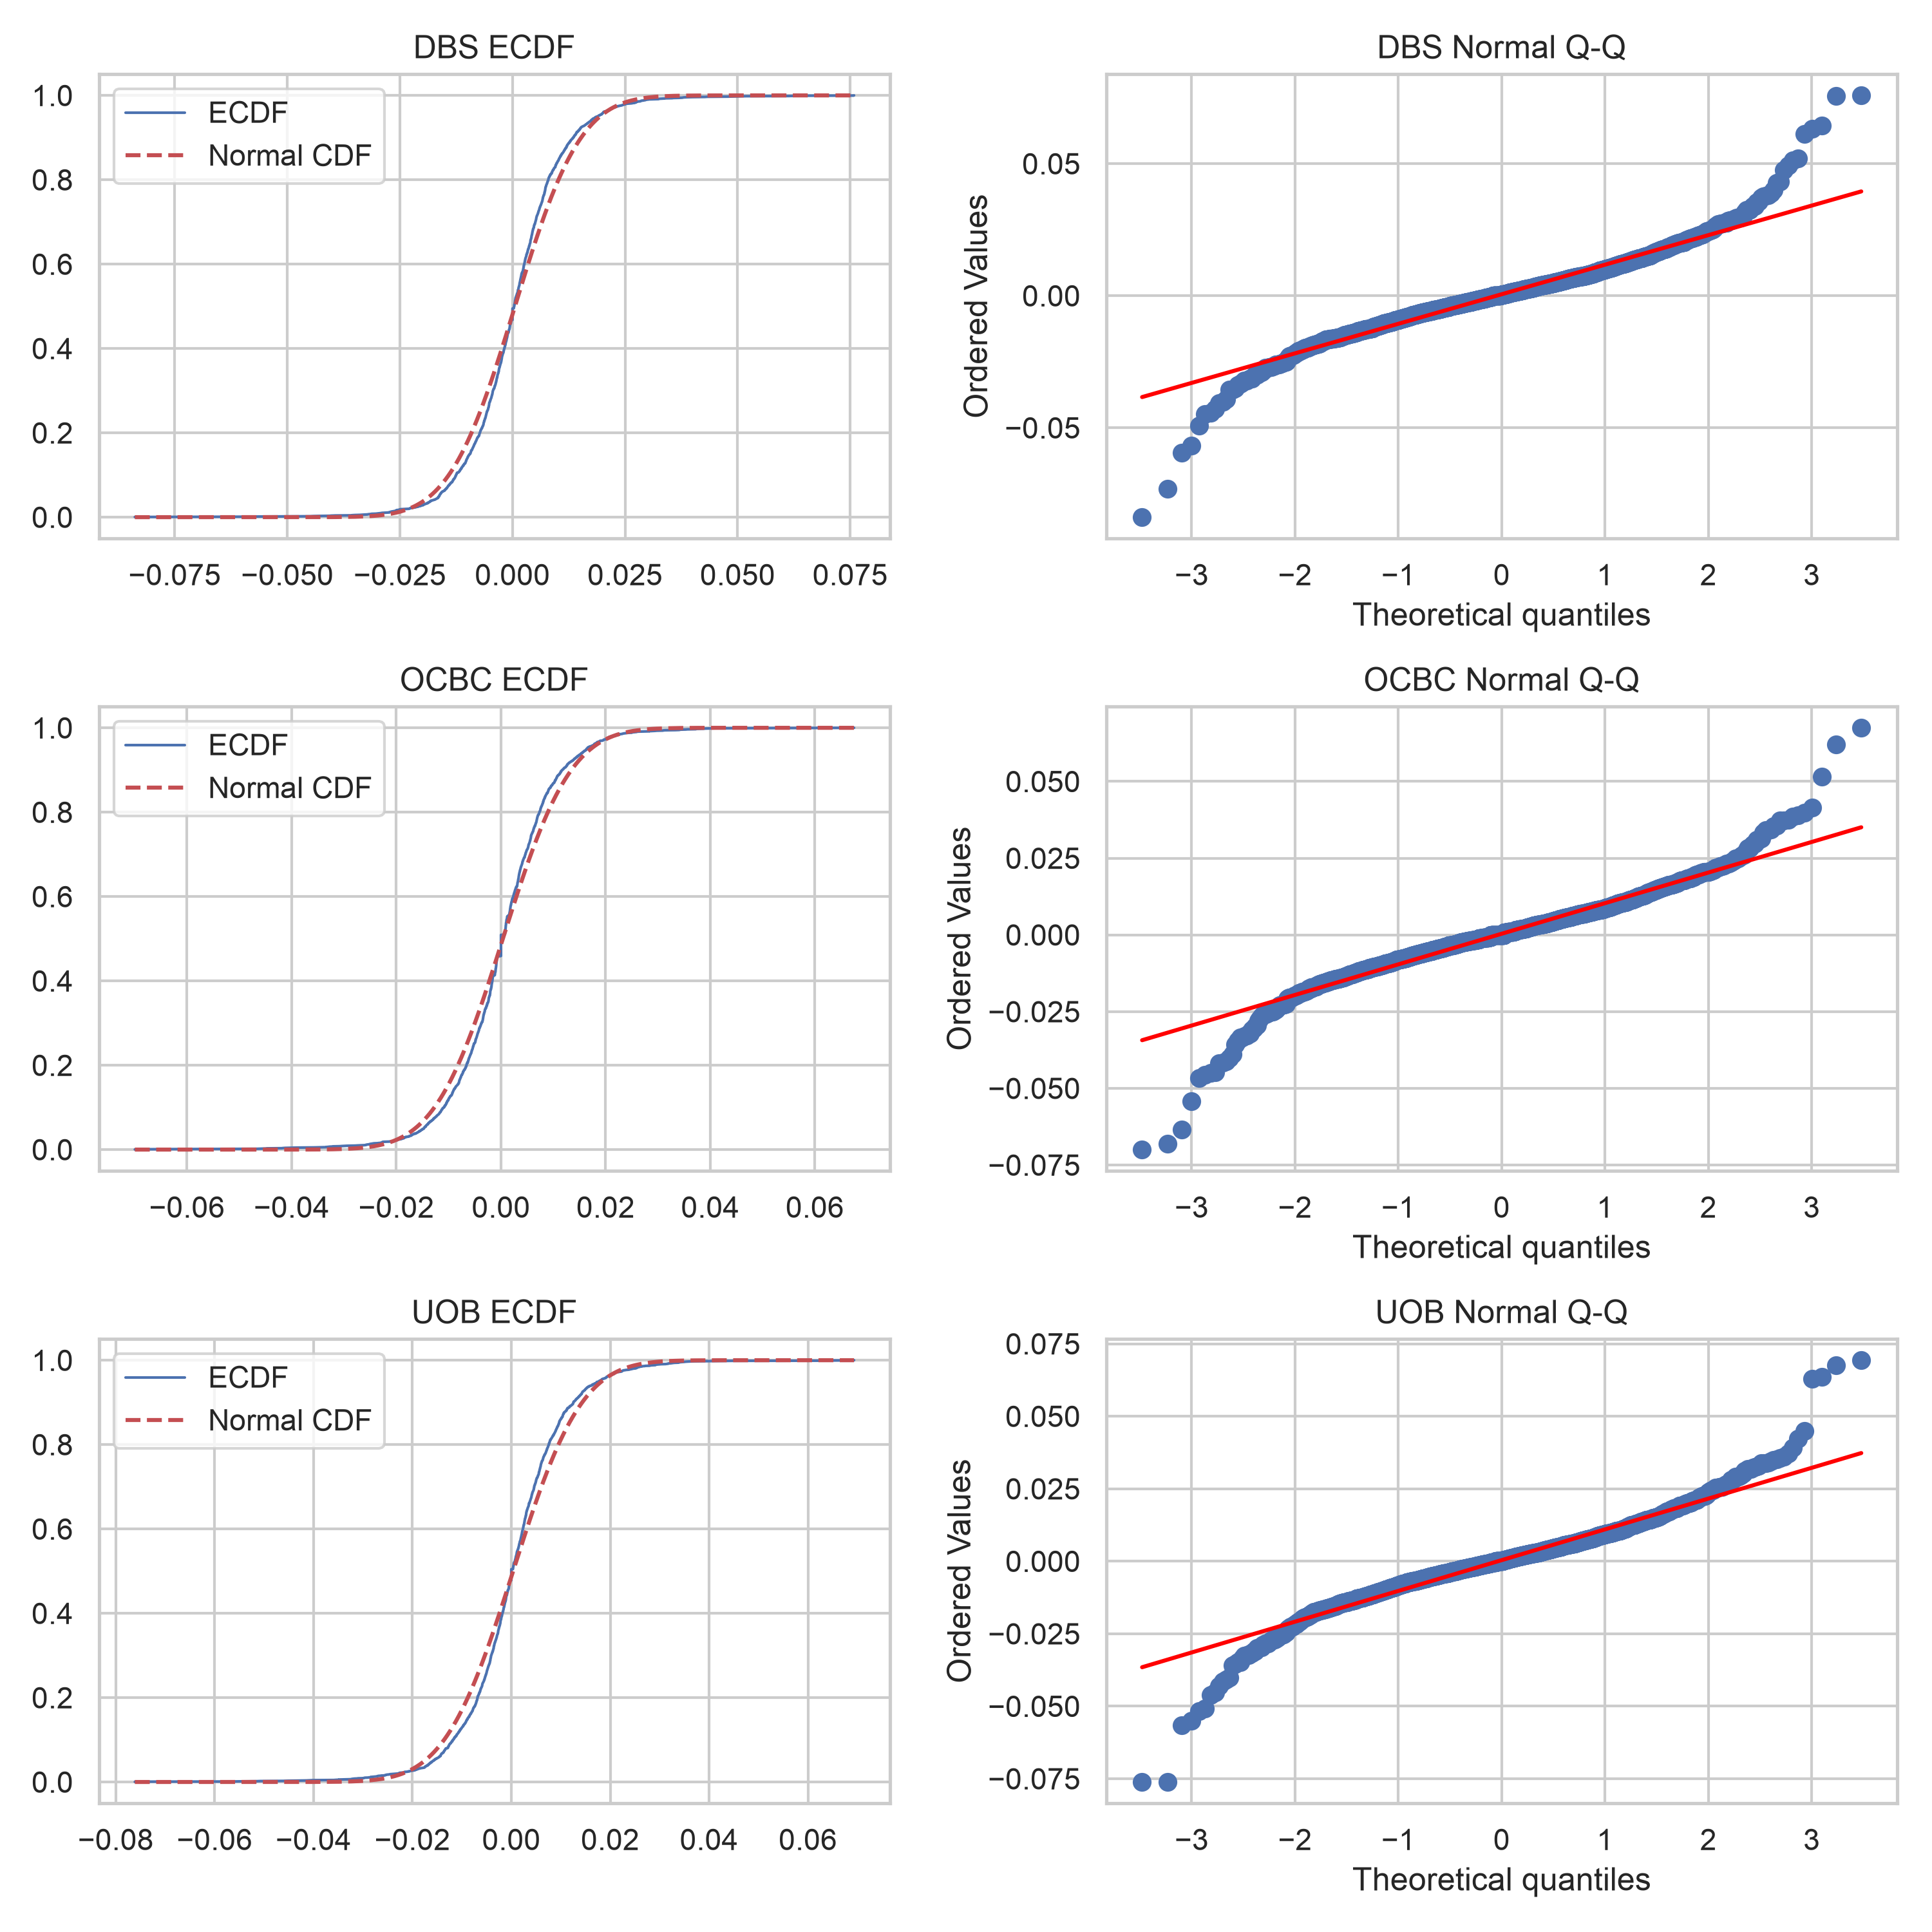

step4_hist_kde_normal.png


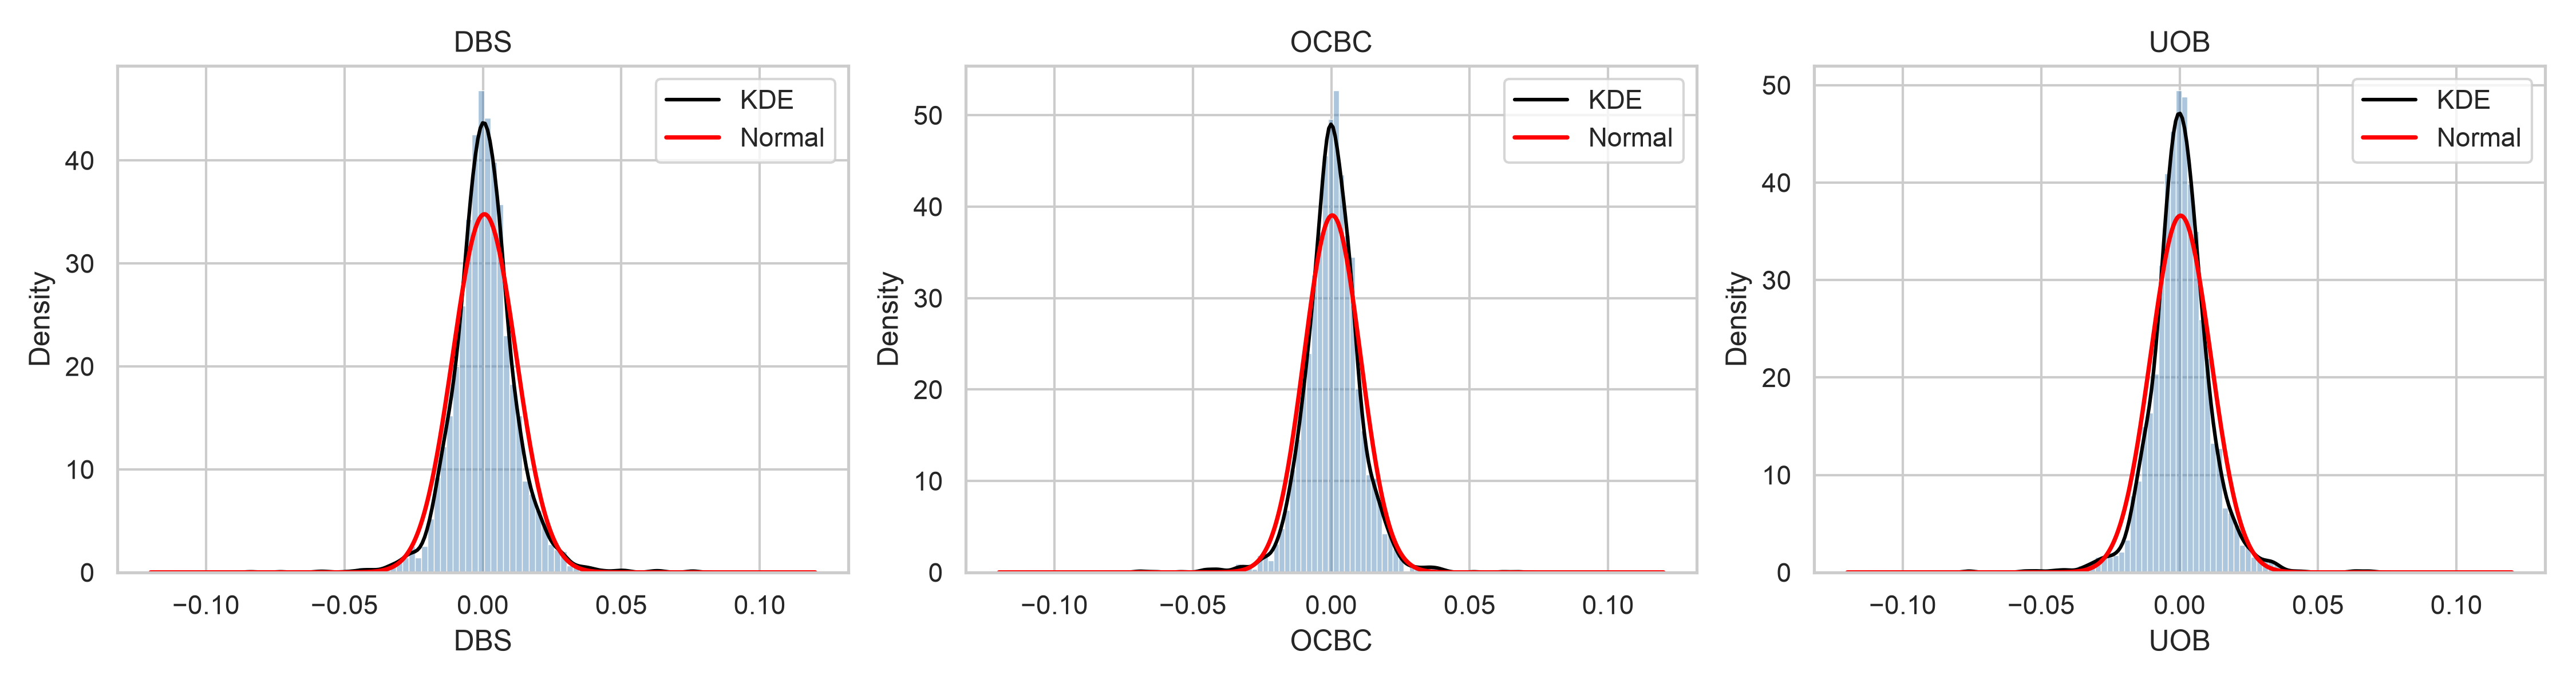

step4_return_series_regimes.png


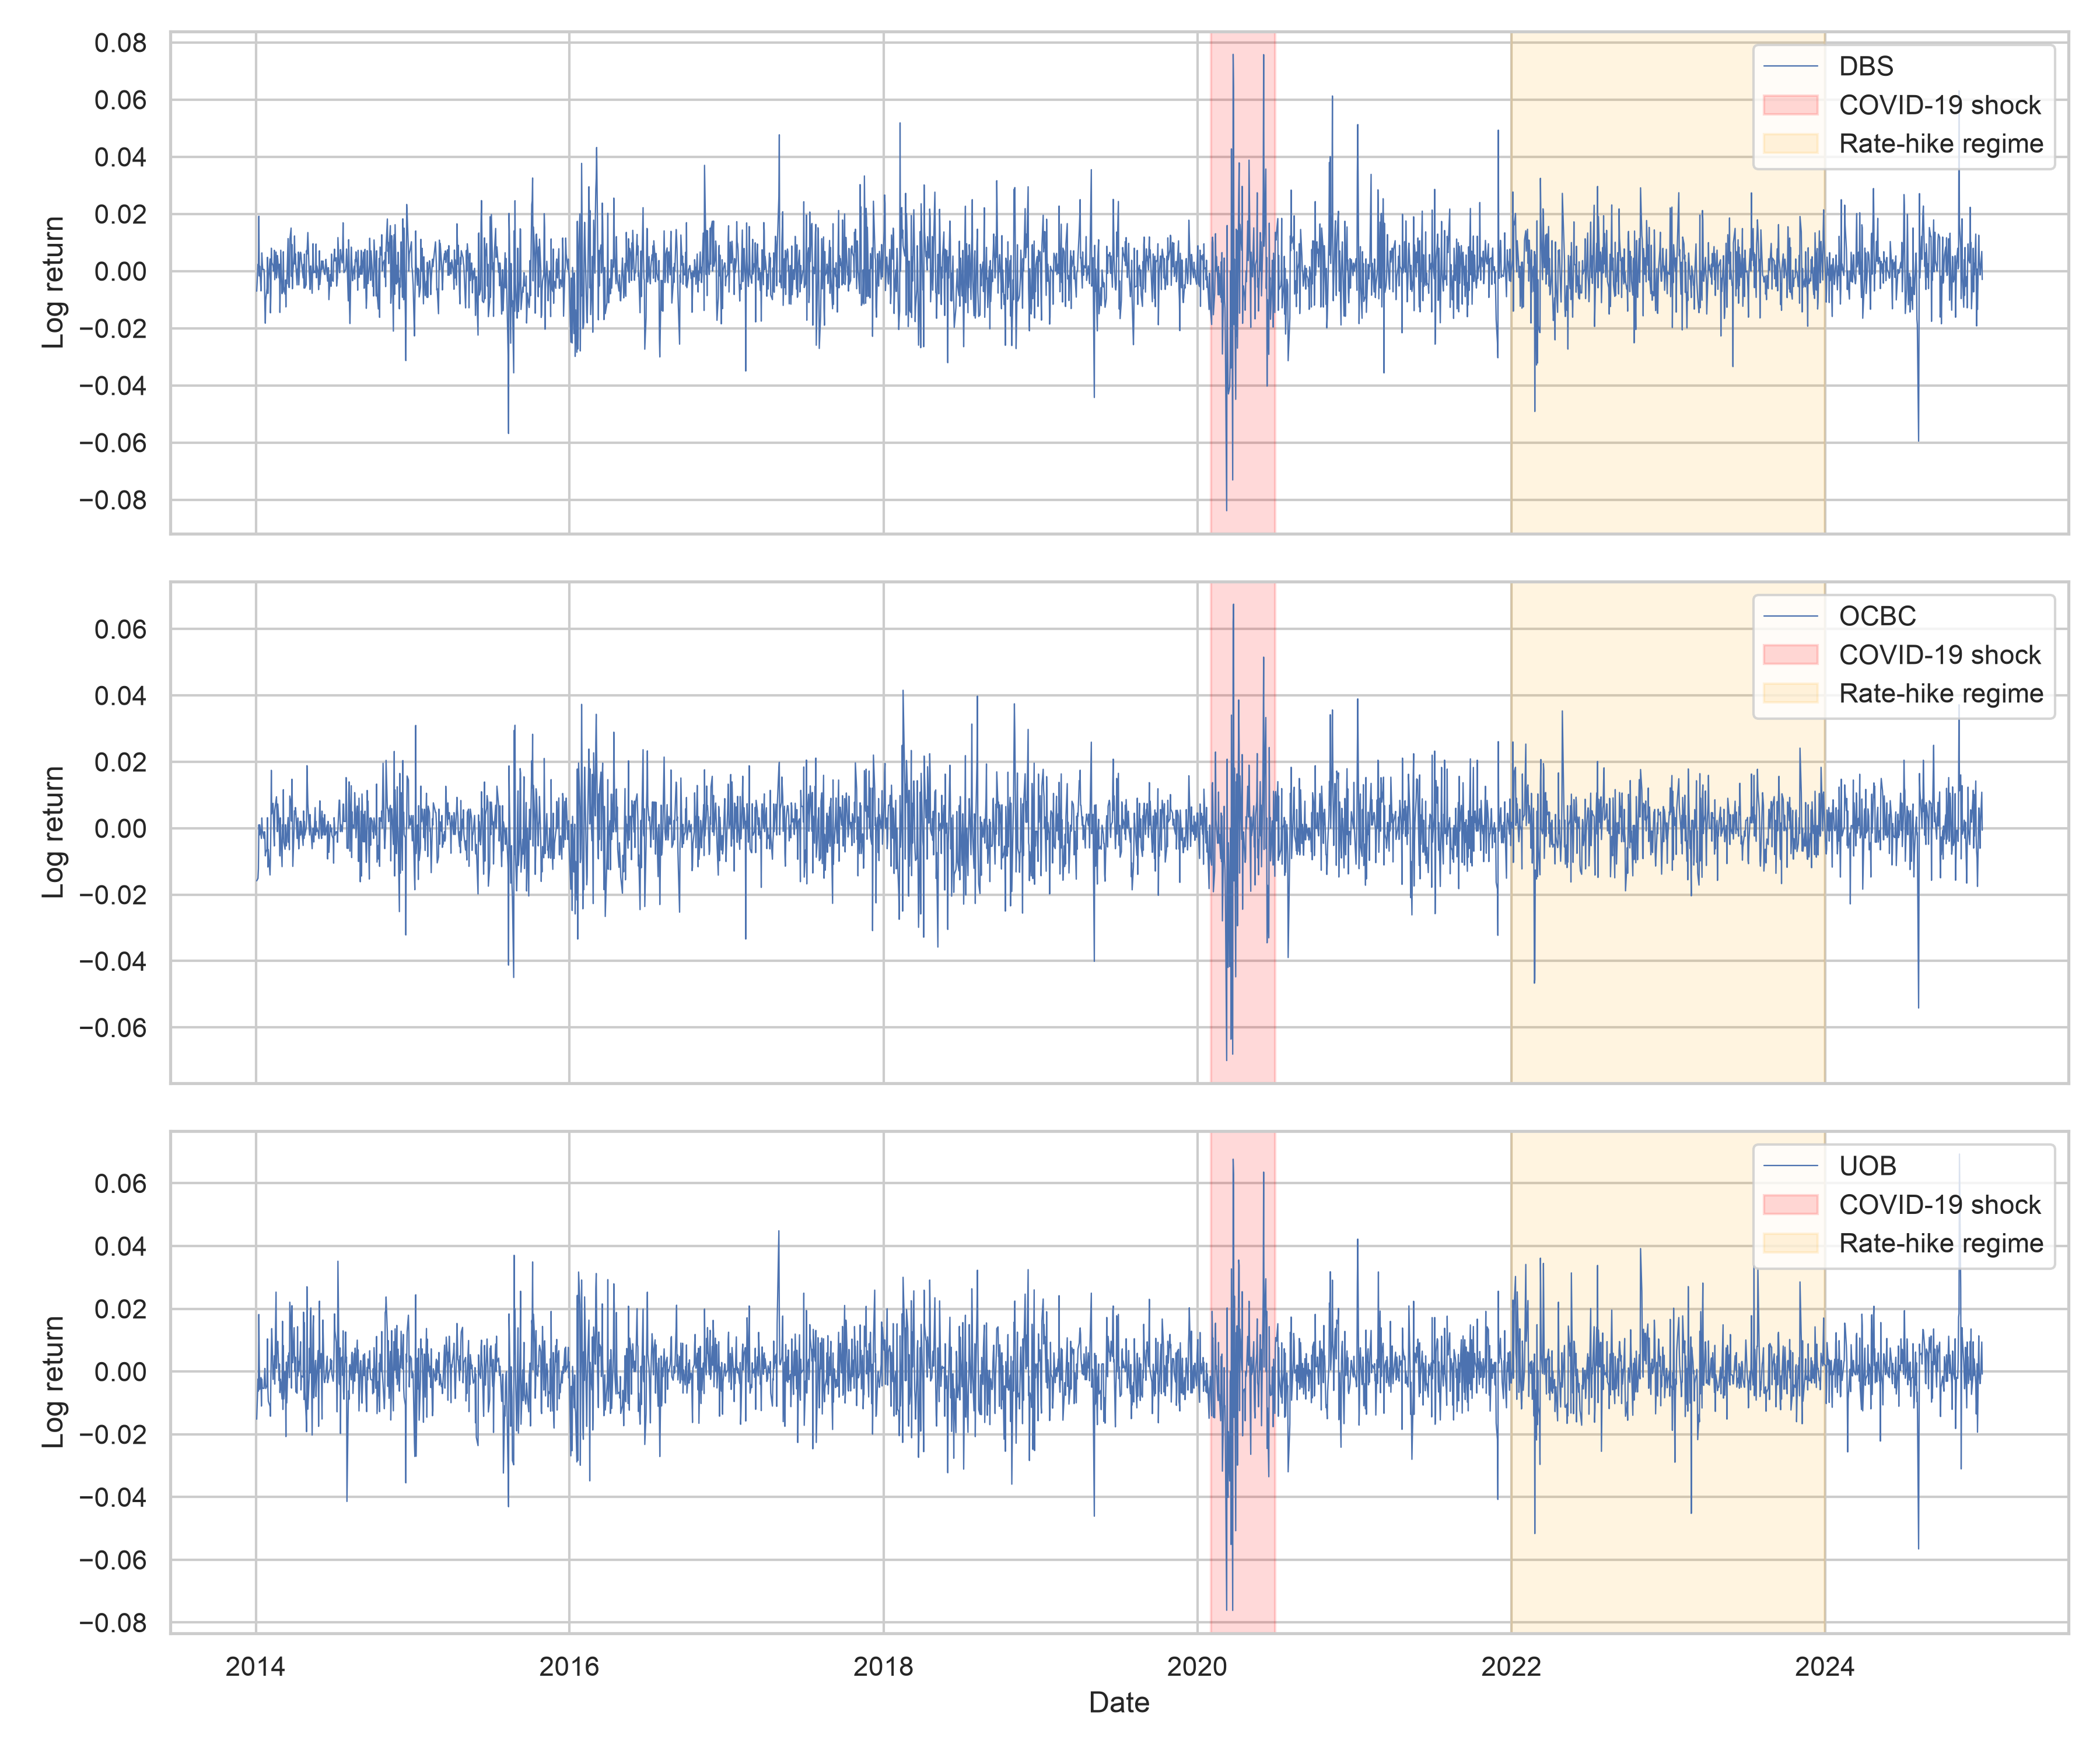

step6_clt_vs_bootstrap_cis.png


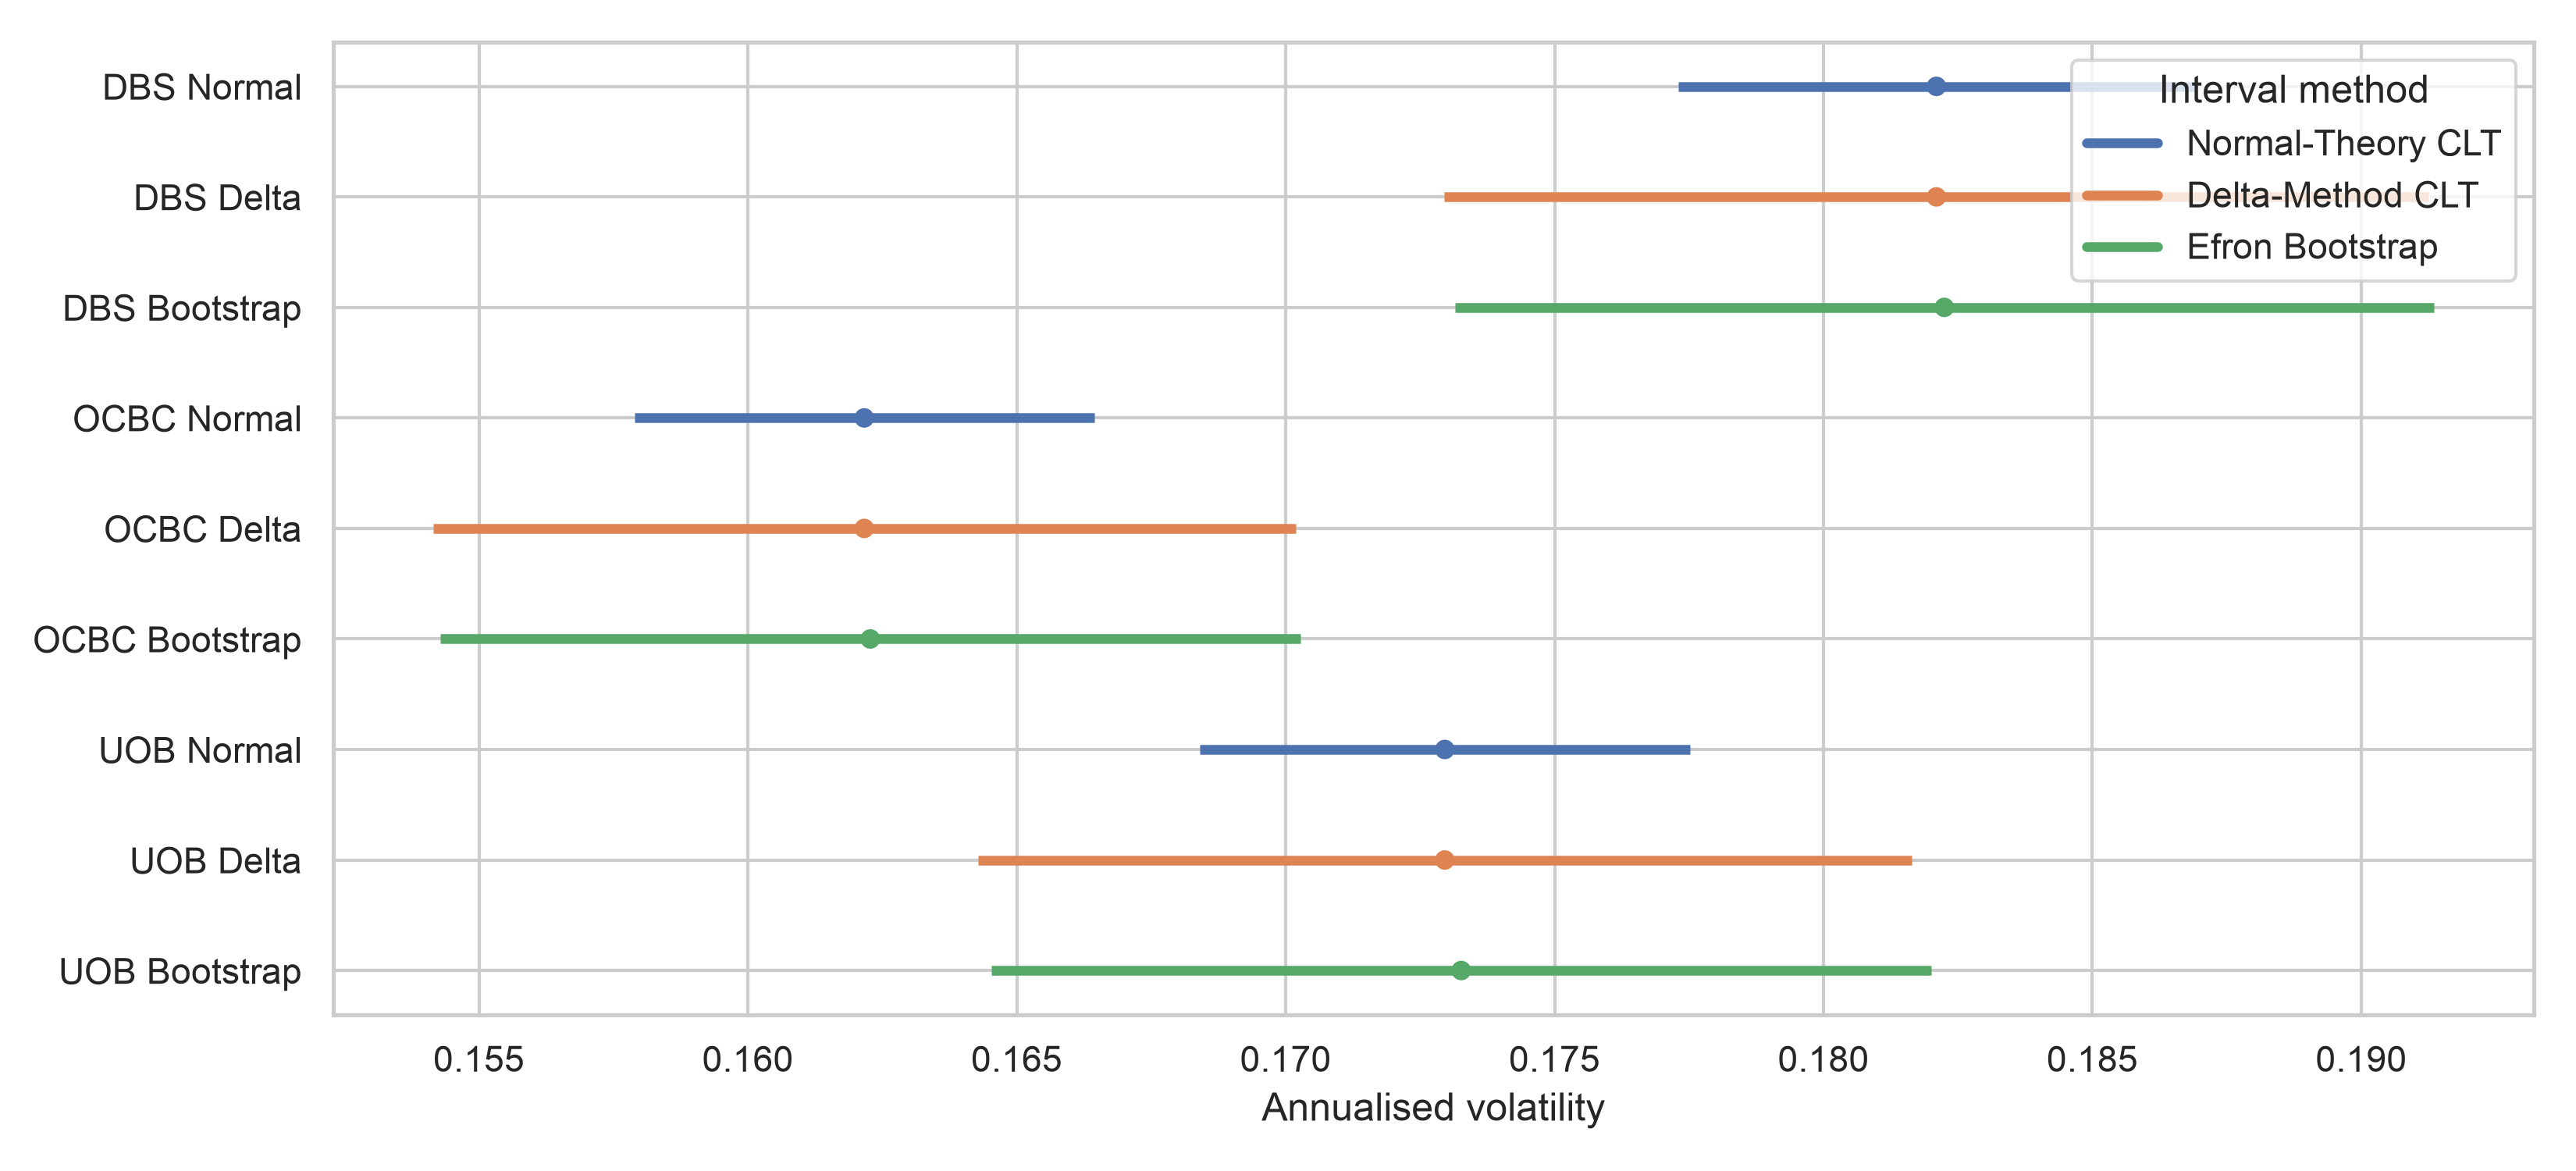

step8_normal_vs_t_qq_ecdf.png


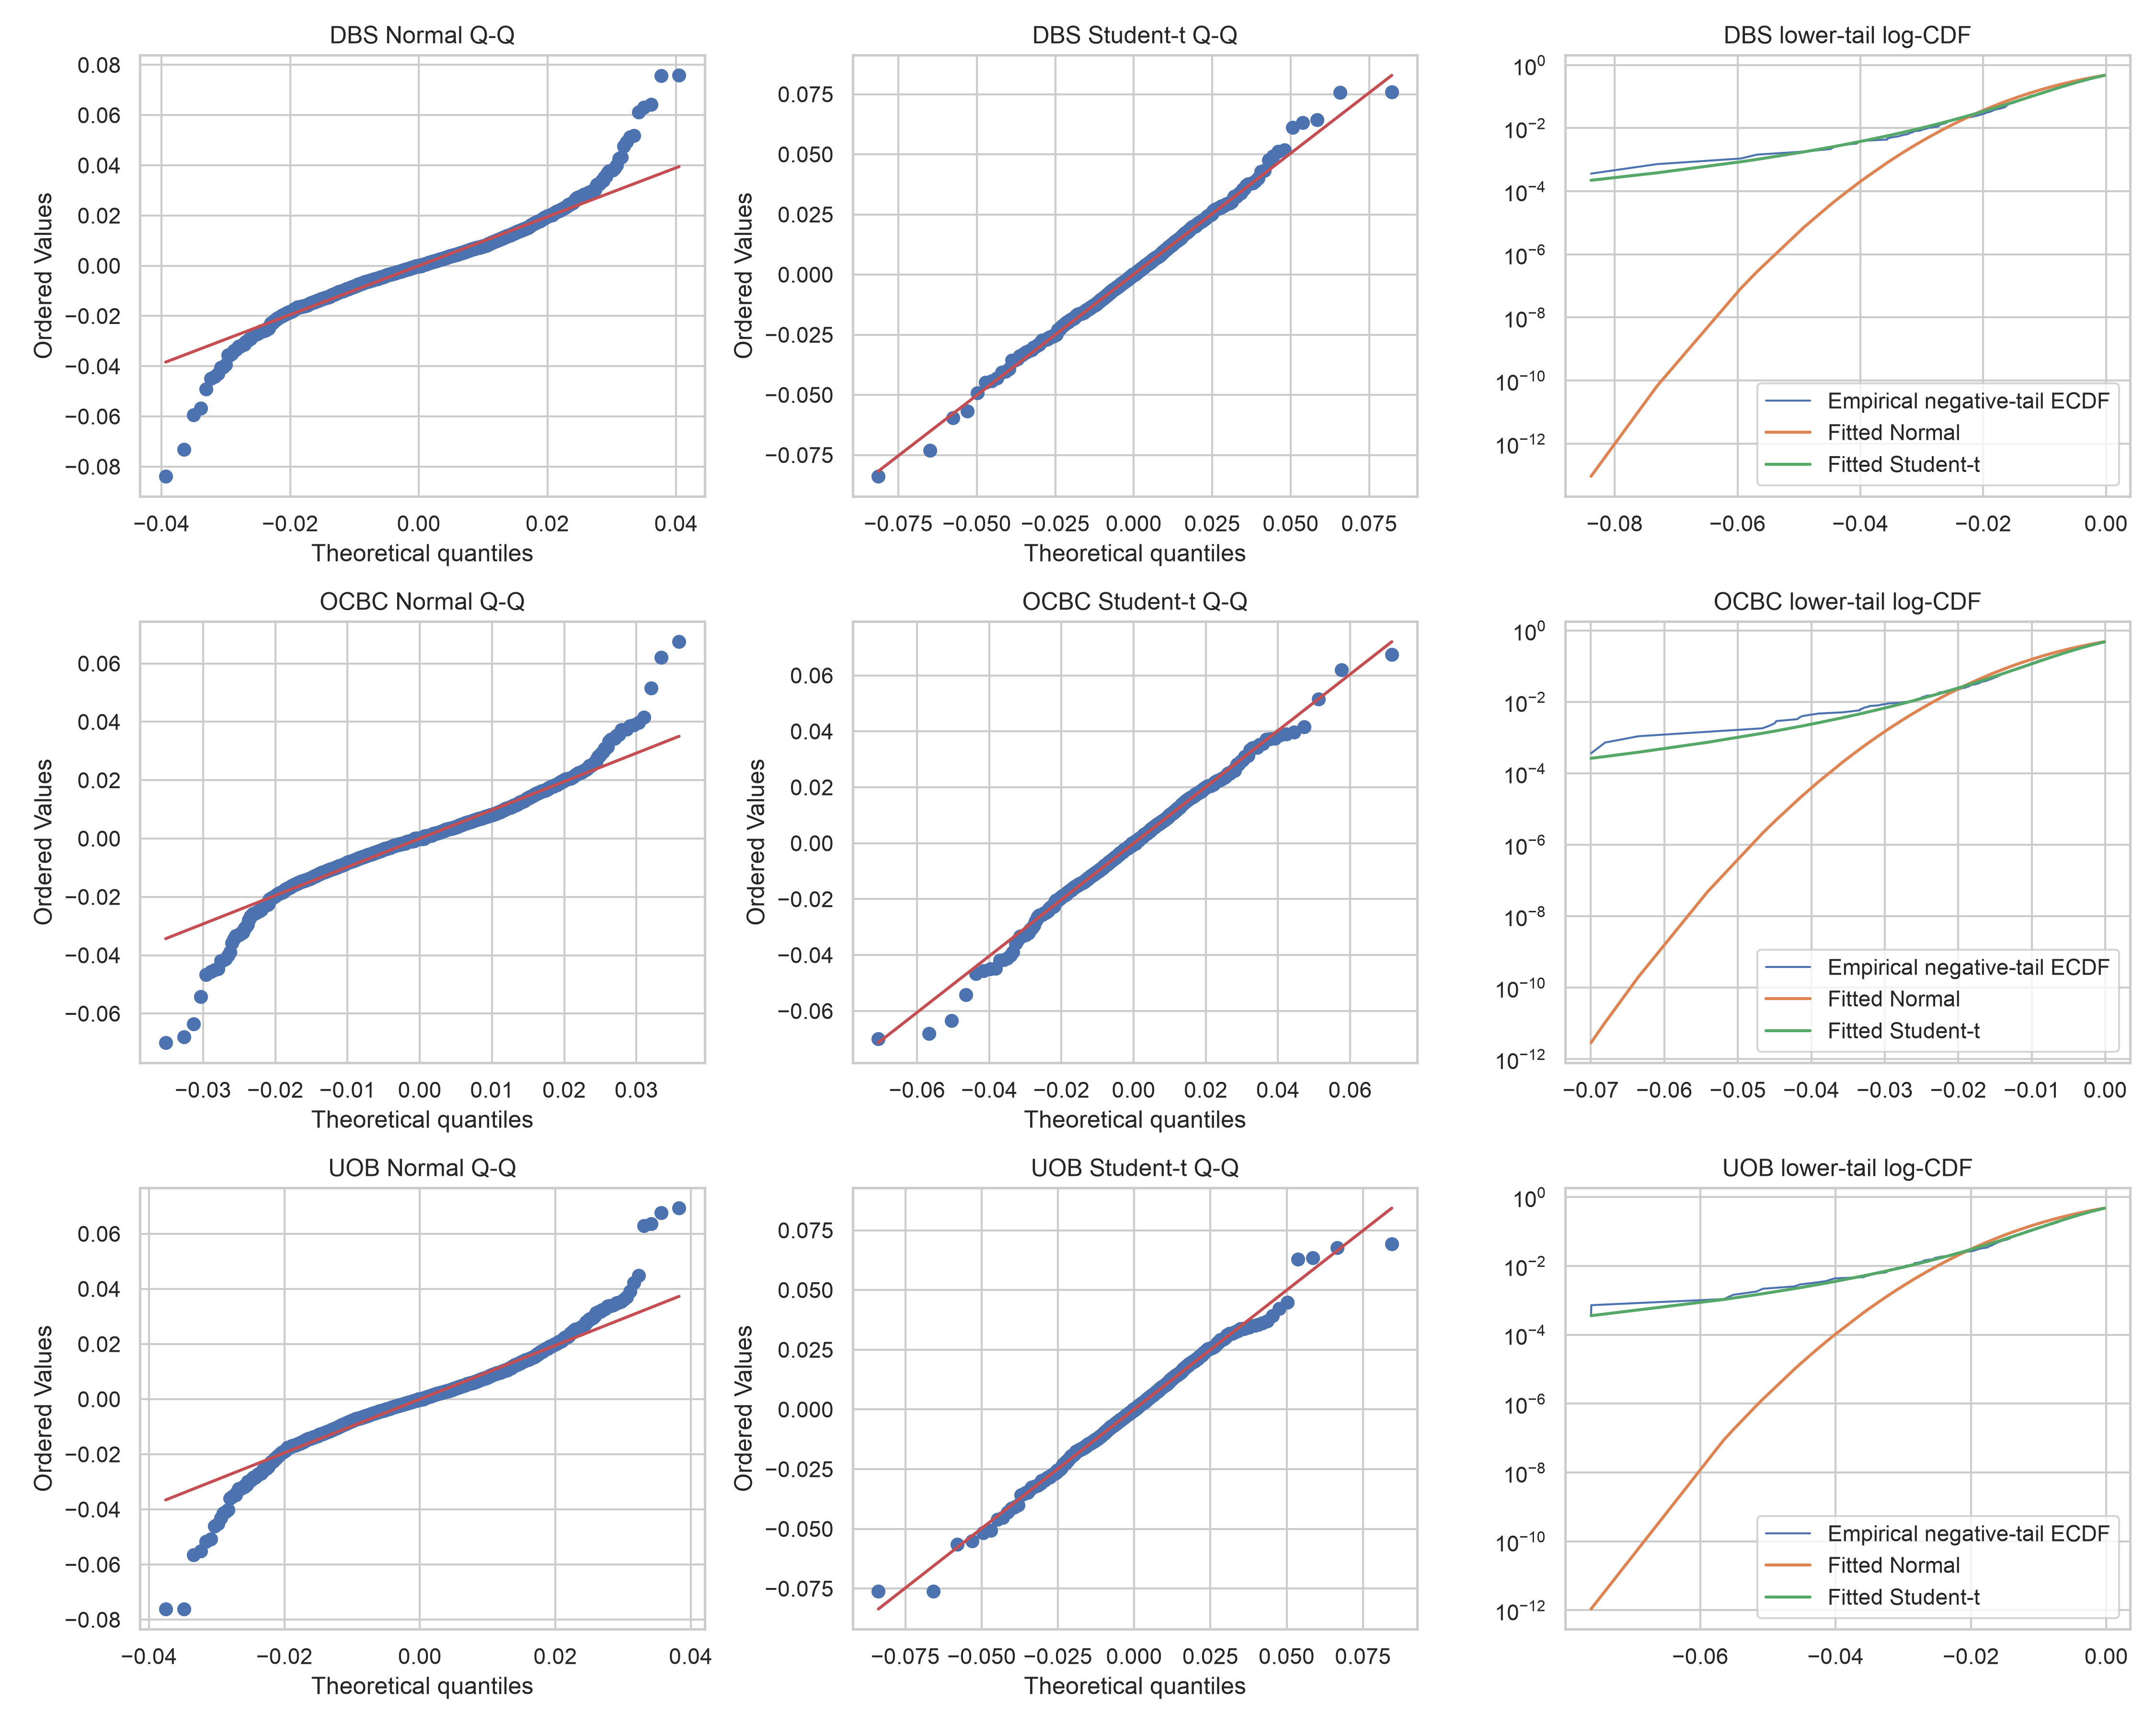

step8_normal_vs_t_qq_ecdf_DBS.png


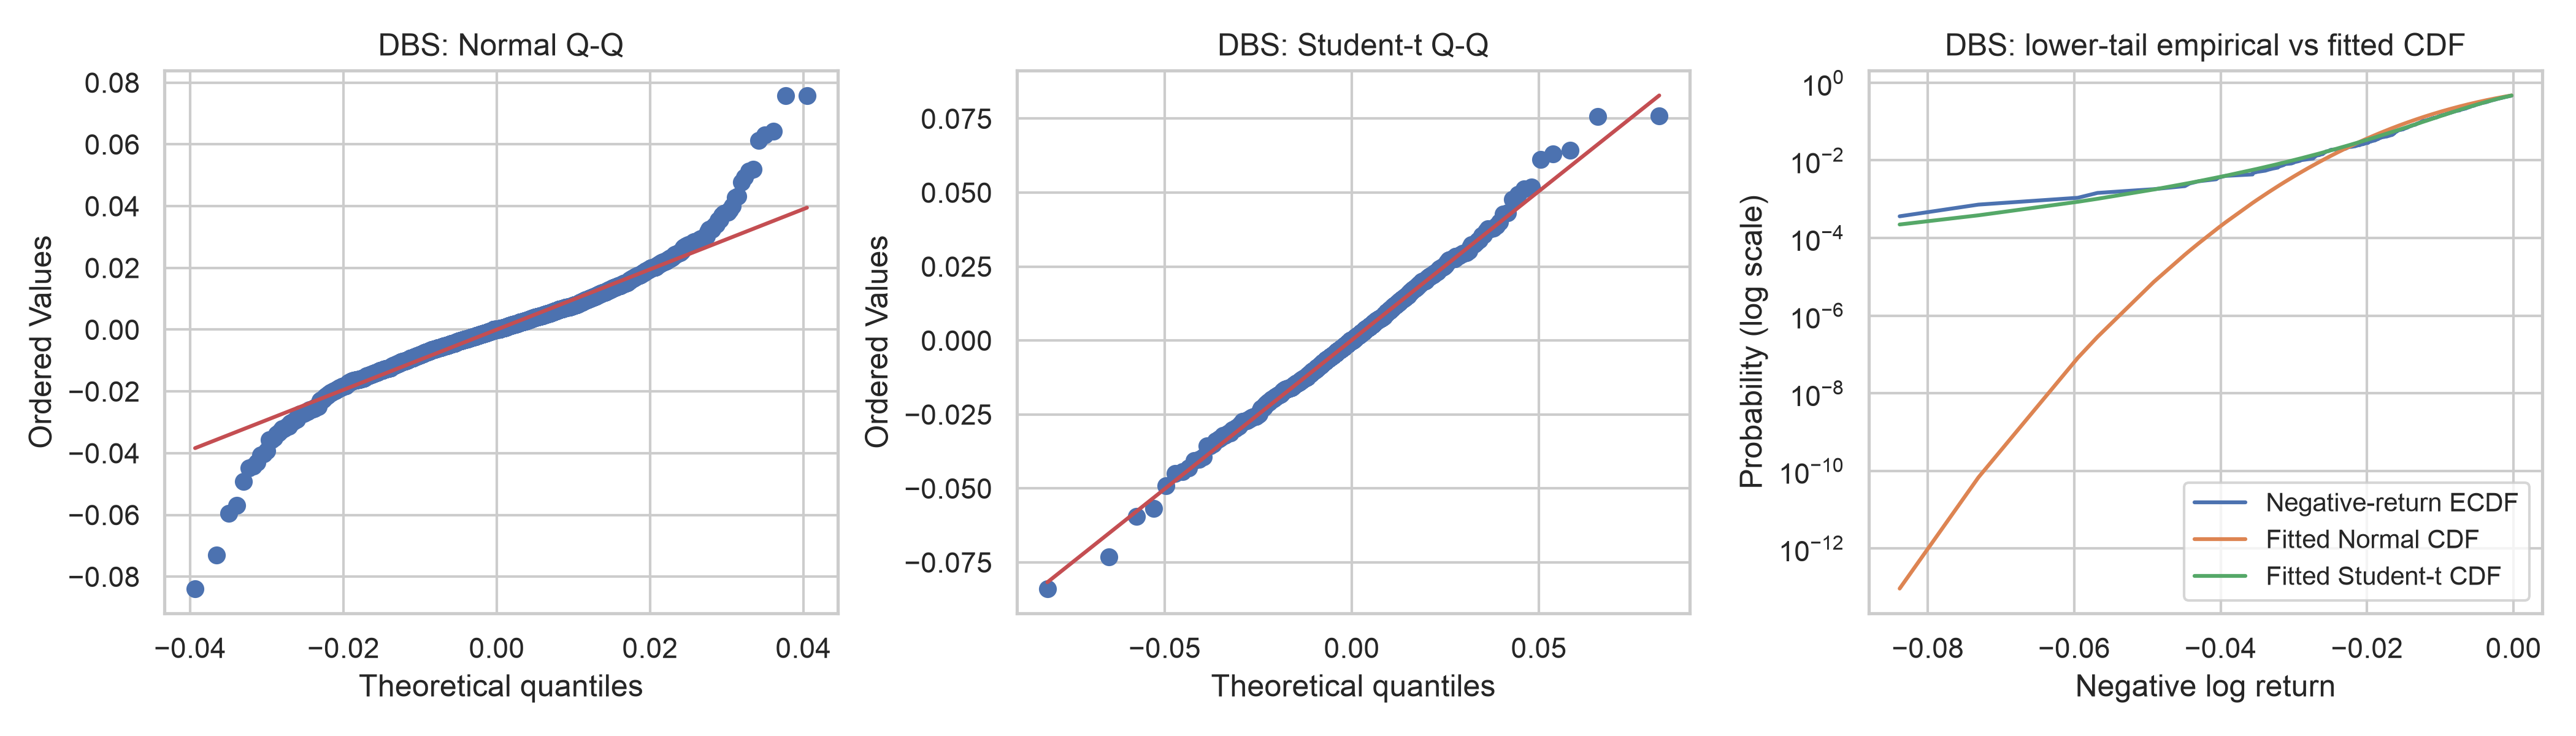

step8_normal_vs_t_qq_ecdf_OCBC.png


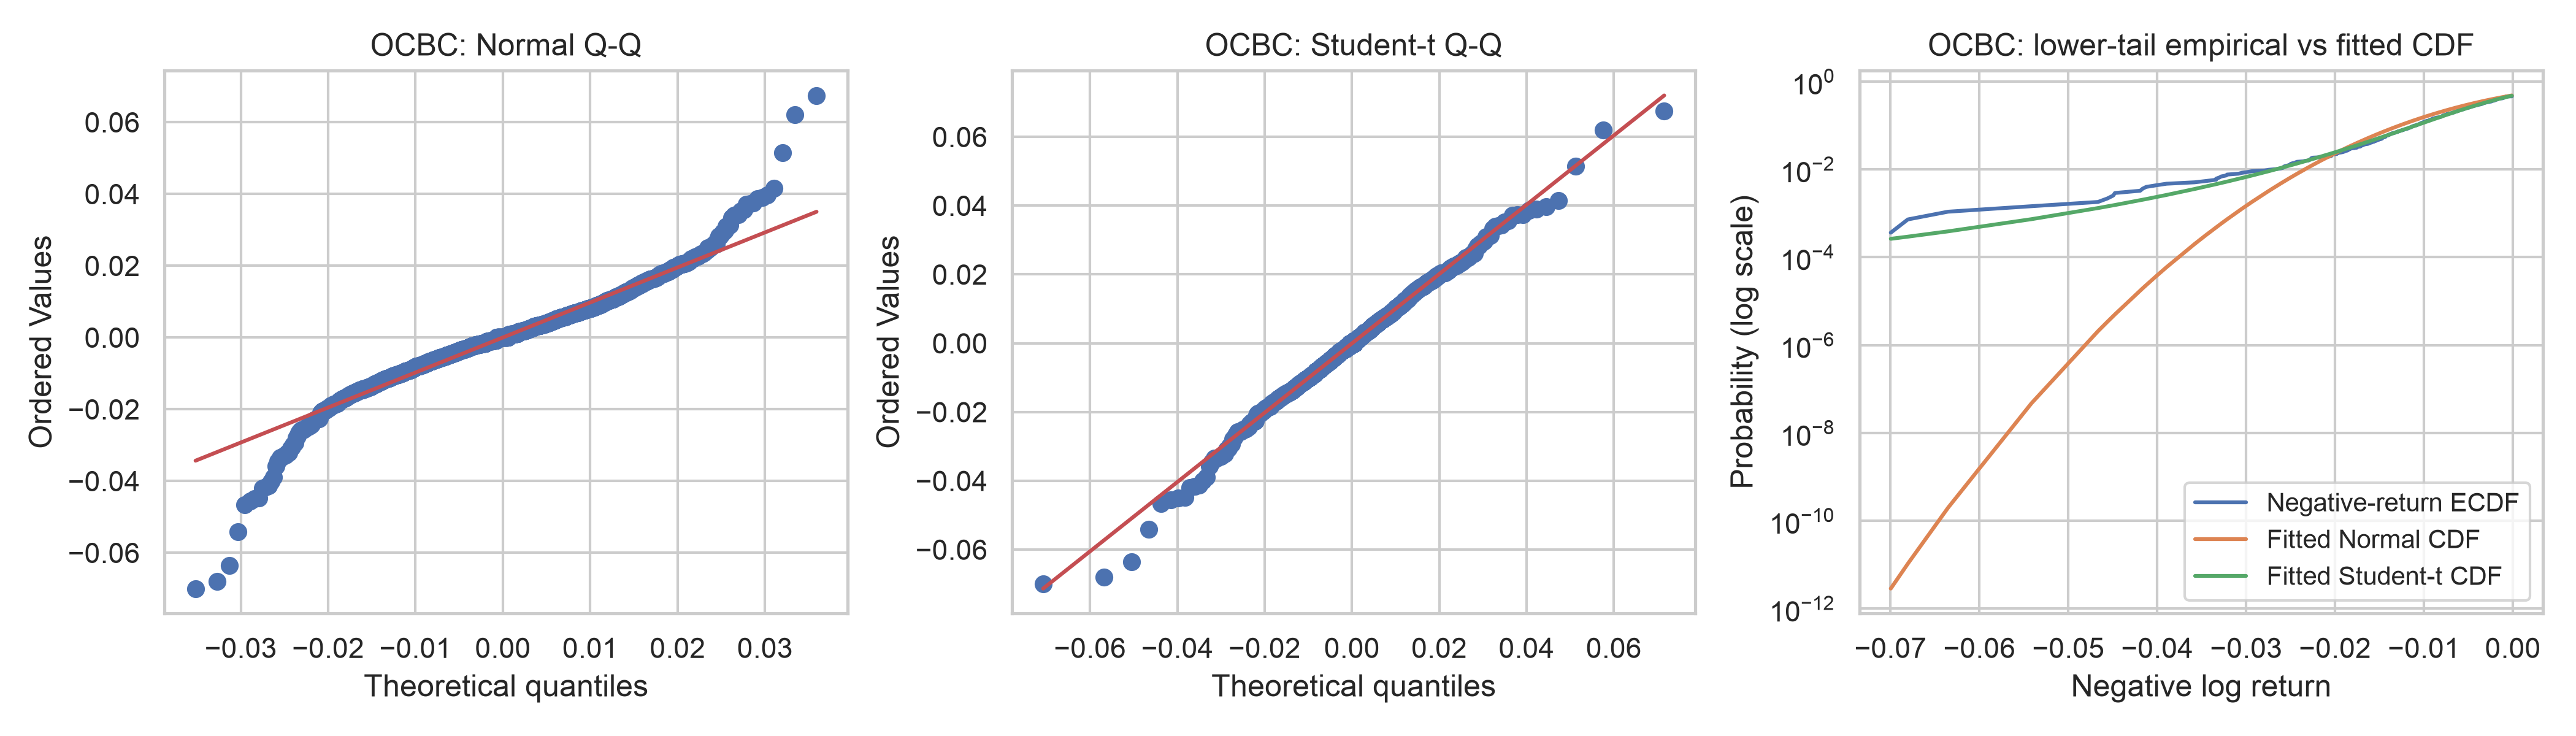

step8_normal_vs_t_qq_ecdf_UOB.png


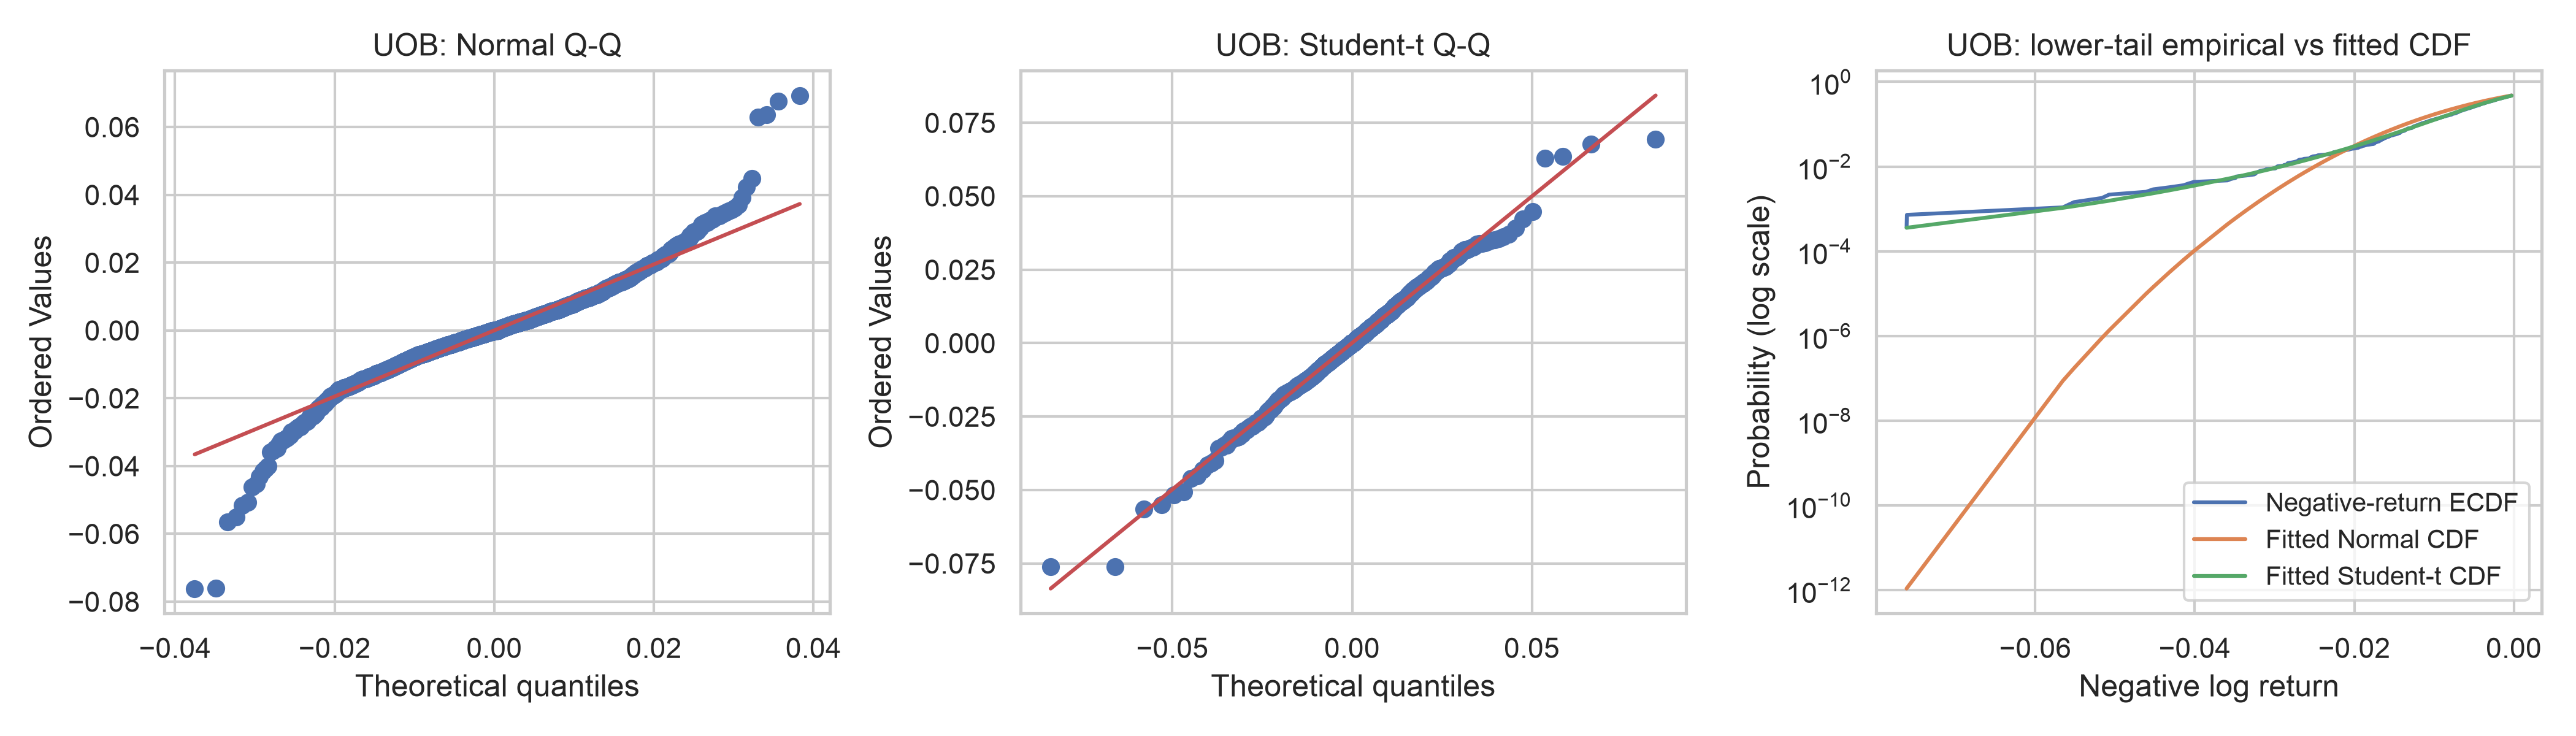

step9_correlation_cis.png


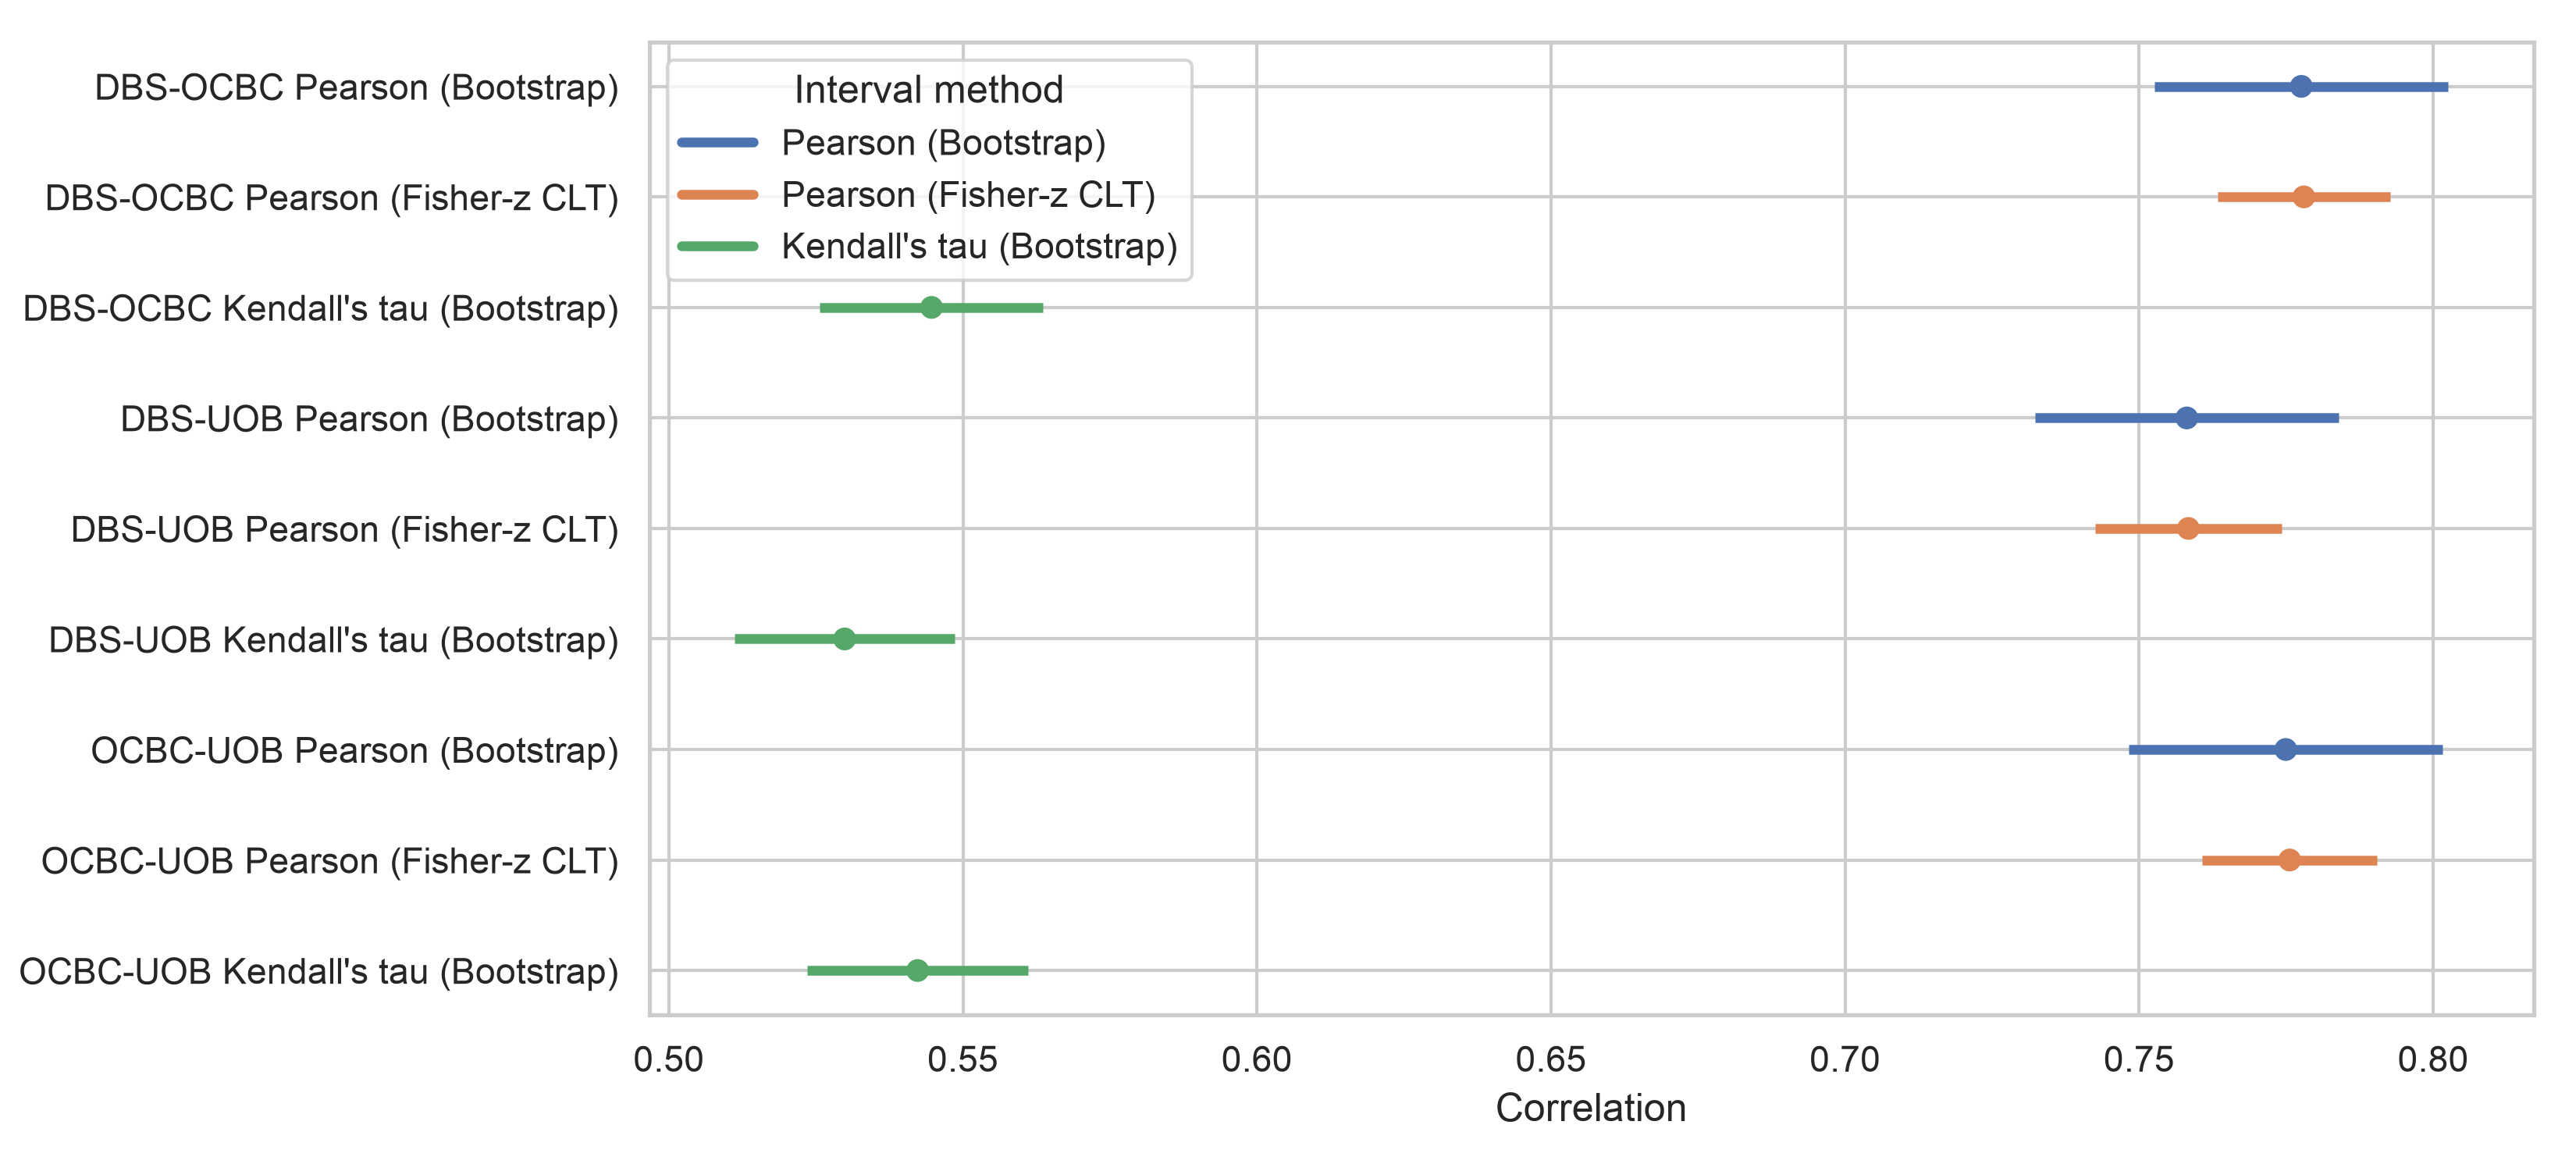

In [4]:
from IPython.display import Image, display
for f in sorted(Path("outputs/figures").glob("*.png")):
    print(f.name)
    display(Image(filename=str(f)))

The figures confirm Normal variance understatement, tail concentration, strong bank co-movement, the COVID volatility shock, and clustered worst-decile co-crashes. Ordinary intervals should be interpreted cautiously because daily serial dependence and volatility clustering remain.

## Executive decisions
Normal-based capital and risk-limit calculations can materially understate extreme returns; Student-t is substantially better but imperfect. The symmetric Student-t captures central concentration and tails better than Normal, yet parametric KS rejects it for OCBC and UOB.